In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


In [2]:
df = pd.read_csv("../data/score_predictor.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [3]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [4]:
for i in ["Hours Studied", "Sleep Hours", "Sample Question Papers Practiced"]:
    print(i, ":", df[i].unique())


Hours Studied : [7 4 8 5 3 6 2 1 9]
Sleep Hours : [9 4 7 5 8 6]
Sample Question Papers Practiced : [1 2 5 6 0 8 3 4 9 7]


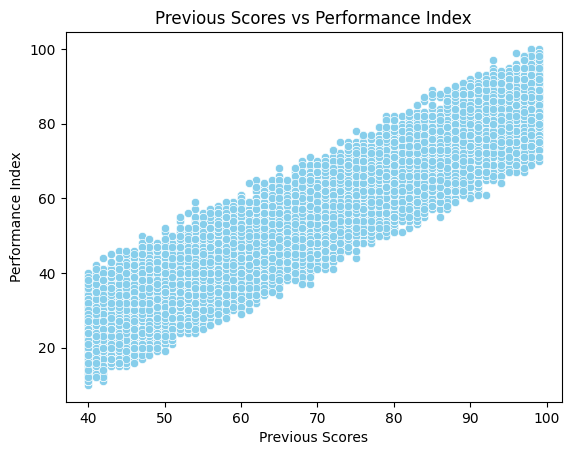

In [5]:
sns.scatterplot(x="Previous Scores", y="Performance Index", color="skyblue", data=df)
plt.title("Previous Scores vs Performance Index")
plt.show()

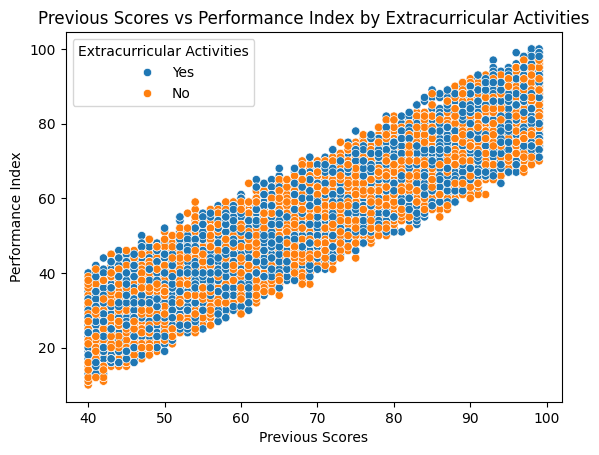

In [6]:
sns.scatterplot(x="Previous Scores", y="Performance Index",hue="Extracurricular Activities", color="skyblue", data=df)
plt.title("Previous Scores vs Performance Index by Extracurricular Activities")
plt.show()

In [7]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes":1, "No":0})


In [8]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [9]:
X = df.drop(columns=['Performance Index'])
y = df['Performance Index']

print("X shape:", X.shape)   # (10000, 5)
print("y shape:", y.shape)   # (10000,)

X shape: (10000, 5)
y shape: (10000,)


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
      X, y,
      test_size=0.2,      # 20% held back for testing
      random_state=42     # fixed seed = same split every run
  )

print("Train size:", X_train.shape[0])   # 8000
print("Test size :", X_test.shape[0])

Train size: 8000
Test size : 2000


In [12]:
model = LinearRegression()       # create the model
model.fit(X_train, y_train)      # learn from training data

print("Training done!")

  # See what weight the model gave each feature
for feature, weight in zip(X.columns, model.coef_):
    print(f"  {feature}: {weight:.4f}")
print(f"  Bias: {model.intercept_:.4f}")

Training done!
  Hours Studied: 2.8525
  Previous Scores: 1.0170
  Extracurricular Activities: 0.6086
  Sleep Hours: 0.4769
  Sample Question Papers Practiced: 0.1918
  Bias: -33.9219


In [13]:
y_pred = model.predict(X_test)   # predict on hidden test data

mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.2f}")    # average error in score points
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")    # 1.0 = perfect, 0 = useless

MAE  : 1.61
RMSE : 2.02
R²   : 0.9890


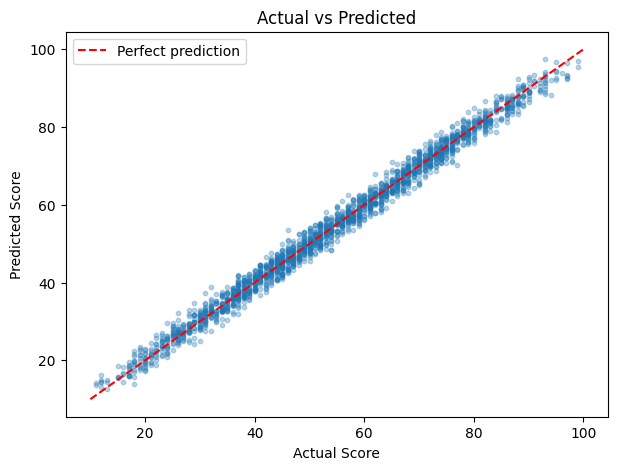

In [14]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)

# Perfect prediction line — all points should be on this
plt.plot([10, 100], [10, 100], 'r--', label='Perfect prediction')

plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

In [15]:
new_student = pd.DataFrame([{
      'Hours Studied': 6,
      'Previous Scores': 75,
      'Extracurricular Activities': 1,   # 1 = Yes
      'Sleep Hours': 7,
      'Sample Question Papers Practiced': 4
  }])

predicted = model.predict(new_student)[0]
print(f"Predicted Performance Index: {predicted:.1f} / 100")

Predicted Performance Index: 64.2 / 100


In [16]:
new_student = pd.DataFrame([{
      'Hours Studied': 9,
      'Previous Scores': 82,
      'Extracurricular Activities': 0,   # 1 = Yes
      'Sleep Hours': 7,
      'Sample Question Papers Practiced': 6
  }])

predicted = model.predict(new_student)[0]
print(f"Predicted Performance Index: {predicted:.1f} / 100")

Predicted Performance Index: 79.6 / 100
